# Project 02 — Apriori-TID Mining

# 1. Khởi tạo môi trường

In [ ]:
import os
import shutil
import shlex
import re
import subprocess
import tempfile
from pathlib import Path
def download_runtime_archive(url, destination):
    subprocess.run(["curl", "-fLsS", "--retry", "2", "--max-time", "240",
                    url, "-o", str(destination)], check=True)
from IPython.display import Image, SVG, Markdown, display

repository_url = "https://github.com/torusama/apriori-tid-mining.git"
repository_branch = "main"

repository = None
for directory in [Path.cwd(), *Path.cwd().parents]:
    if (directory / "scripts" / "visual_pipeline.jl").is_file():
        repository = directory
        break

if repository is None:
    repository = Path.cwd() / "apriori-tid-mining"
    uploaded_zip = Path("/content/apriori-tid-mining-reviewed.zip")
    if not uploaded_zip.is_file():
        uploaded_zip = Path("/content/apriori-tid-mining-ready.zip")
    if not uploaded_zip.is_file():
        uploaded_zip = Path("/content/apriori-tid-mining.zip")
    if uploaded_zip.is_file():
        subprocess.run(["unzip", "-o", str(uploaded_zip), "-d", str(Path.cwd())], check=True)
    elif not repository.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", repository_branch,
                        repository_url, str(repository)], check=True)

for required_file in ["demo.jl", "scripts/fetch_datasets.jl", "scripts/plot_results.jl",
                      "scripts/visual_pipeline.jl", "scripts/run_all_tests.jl"]:
    if not (repository / required_file).is_file():
        raise RuntimeError("The repository is missing the integrated files. Upload the ZIP or update the GitHub branch.")

julia = shutil.which("julia")
if julia is None:
    julia_version = "1.10.10"
    installation_directory = Path(tempfile.gettempdir()) / ("julia-" + julia_version)
    julia = str(installation_directory / "bin" / "julia")
    if not Path(julia).is_file():
        with tempfile.TemporaryDirectory() as download_directory:
            archive = Path(download_directory) / "julia.tar.gz"
            download_runtime_archive(f"https://julialang-s3.julialang.org/bin/linux/x64/1.10/julia-{julia_version}-linux-x86_64.tar.gz", archive)
            subprocess.run(["tar", "-xzf", str(archive), "-C", str(installation_directory.parent)], check=True)

# Dùng Java 25+ cho SPMF; trên Colab tự cài JRE nếu cần.
def java_is_compatible():
    if shutil.which("java") is None:
        return False
    version = subprocess.run(["java", "-version"], capture_output=True, text=True, check=True)
    major = re.search(r'version "(\d+)', version.stderr + version.stdout)
    return major is not None and int(major.group(1)) >= 25

if not java_is_compatible():
    if not Path("/content").is_dir():
        raise RuntimeError("Install Java 25+ and add it to PATH before running this notebook locally.")
    java_directory = Path(tempfile.gettempdir()) / "apriori-openjdk25"
    java_directory.mkdir(parents=True, exist_ok=True)
    if not (java_directory / "bin/java").is_file():
        with tempfile.TemporaryDirectory() as download_directory:
            archive = Path(download_directory) / "java25.tar.gz"
            java_url = "https://download.java.net/java/GA/jdk25.0.2/b1e0dfa218384cb9959bdcb897162d4e/10/GPL/openjdk-25.0.2_linux-x64_bin.tar.gz"
            download_runtime_archive(java_url, archive)
            subprocess.run(["tar", "-xzf", str(archive), "-C", str(java_directory),
                            "--strip-components=1"], check=True)
    os.environ["JAVA_HOME"] = str(java_directory)
    os.environ["PATH"] = str(java_directory / "bin") + os.pathsep + os.environ["PATH"]

if not java_is_compatible():
    raise RuntimeError("SPMF needs Java 25 or newer.")
subprocess.run(["java", "-version"], check=True)

workspace = Path(tempfile.mkdtemp(prefix="apriori-demo-"))
raw_data = repository / "data" / "raw"

def run_julia(environment, script, *arguments, extra_environment=None, threads=None):
    command = [julia, "--startup-file=no"]
    if threads is not None:
        command.append(f"--threads={threads}")
    command.extend([f"--project={repository / environment}", str(repository / script)])
    for argument in arguments:
        command.append(str(argument))
    print(shlex.join(command), flush=True)
    subprocess.run(command, cwd=repository, check=True, env=extra_environment)

def instantiate(environment):
    subprocess.run([julia, "--startup-file=no", f"--project={repository / environment}",
                    "-e", "using Pkg; Pkg.instantiate()"], cwd=repository, check=True,
                   env=os.environ | {"JULIA_NUM_PRECOMPILE_TASKS": "2"})

print(subprocess.check_output([julia, "--version"], text=True).strip())
print("Repository:", repository)
instantiate(".")
instantiate("evaluation_environment")
instantiate("visual_environment")
import tomllib
manifest_path = repository / "result/final/run_manifest.toml"
if manifest_path.is_file():
    print(manifest_path.read_text())


julia version 1.12.6
Repository: /content/apriori-tid-mining


benchmark_config = "configs/benchmark.toml"
captured_utc = "2026-11-24T13:02:40.844"
dataset_checksums = "benchmark/datasets.csv"
julia_threads = 1
julia_version = "1.13.4"
memory_scope = "Peak RSS of a fresh Julia CLI, including input and output"
runtime_scope = "Julia median warmed mine(); SPMF median internal reported time"
seed = 42
source_fingerprint_sha256 = "0a320ab7a63ba64bc69c2a76683b45b7ccd8d0a20ff53b2671be1c501c5a5799"
source_revision = "c633d4f33d20f639bf1facb147745da7dbd2a20f"
test_log = "../correctness/final-tests.txt"

[source_files_sha256]
"Manifest.toml" = "9d53374c63ef6ee919e2af2317f4185c4a5f75339d323d649521498666e51d24"
"Project.toml" = "bcbe2c5d1be5d647e39f811e50762f85d35992230b9f5bf616c098c05afb7f94"
"configs/benchmark.toml" = "6f15070707fb108f95a7aa07a0e256d106c1410f9bc07b9d9ebf97a33c8d988e"
"scripts/measure_retail_processes.jl" = "ecb8f53c07b6f68d66a356d5f534d63ab46c5638b53fa129203ebcef2e15b5d7"
"scripts/run_benchmark.jl" = "95886f46c04f44a6e3de0e0814e6ae1c3bfefa

## 2. Kiểm tra Basic và Optimized
Cùng một dữ liệu, cùng minsup 60%. Hai file kết quả phải trùng hoàn toàn.

In [ ]:
for implementation in ("basic", "optimized"):
    run_julia(".", "demo.jl", "--minsup", "0.6", repository / "data/toy/sample.txt",
              "--output", workspace / f"{implementation}.txt", "--implementation", implementation)

basic_result = (workspace / "basic.txt").read_text()
assert basic_result == (workspace / "optimized.txt").read_text()
print(basic_result)


/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining /content/apriori-tid-mining/demo.jl --minsup 0.6 /content/apriori-tid-mining/data/toy/sample.txt --output /tmp/apriori-demo-zrqz1qsr/basic.txt --implementation basic


/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining /content/apriori-tid-mining/demo.jl --minsup 0.6 /content/apriori-tid-mining/data/toy/sample.txt --output /tmp/apriori-demo-zrqz1qsr/optimized.txt --implementation optimized


1 #SUP: 4
1 2 #SUP: 3
1 3 #SUP: 3
2 #SUP: 4
2 3 #SUP: 3
3 #SUP: 4



## 3. Kiểm thử
Chạy đúng điểm vào `julia --project=. test/runtests.jl` theo đề. Java 25+ được chuẩn bị ở bước 1; toàn bộ test core, SPMF và ảnh phải hoàn thành. Nếu lỗi, cell báo lỗi thay vì ghi nhận pass hoặc tự bỏ qua.


In [ ]:
run_julia(".", "test/runtests.jl")


/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining /content/apriori-tid-mining/test/runtests.jl


## 4. Benchmark — tải dữ liệu và chạy lại
Tải bốn dataset FIMI, chuẩn hóa định dạng SPMF, kiểm tra số giao dịch, số item và SHA-256 so với dữ liệu thực nghiệm đã lưu. Không cần upload dataset gốc lên GitHub.


In [ ]:
run_julia("evaluation_environment", "scripts/fetch_datasets.jl", "benchmark", "--root", raw_data)
benchmark_input_directory = raw_data / "benchmark"


/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining/evaluation_environment /content/apriori-tid-mining/scripts/fetch_datasets.jl benchmark --root /content/apriori-tid-mining/data/raw


### 4.1. Kiểm tra trực tiếp trên bốn dataset
Chạy Basic và Optimized, so từng itemset và support với SPMF ở một mức minsup cao của mỗi dataset. Đây là kiểm tra nhanh trên dữ liệu thật, không thay thế toàn bộ thực nghiệm 5 mức minsup.


In [ ]:
benchmark_quick_cases = [
    ("chess", "0.96"),
    ("mushroom", "0.75"),
    ("retail", "0.05"),
    ("T10I4D100K", "0.045"),
]
spmf_jar = repository / "tools/spmf.jar"
for dataset_name, minimum_support in benchmark_quick_cases:
    print(f"\n{dataset_name}: minsup = {minimum_support}", flush=True)
    run_julia(".", "scripts/compare_spmf.jl", spmf_jar,
              benchmark_input_directory / f"{dataset_name}.txt", minimum_support, threads=1)



chess: minsup = 0.96


/usr/local/bin/julia --startup-file=no --threads=1 --project=/content/apriori-tid-mining /content/apriori-tid-mining/scripts/compare_spmf.jl /content/apriori-tid-mining/tools/spmf.jar /content/apriori-tid-mining/data/raw/benchmark/chess.txt 0.96



mushroom: minsup = 0.75


/usr/local/bin/julia --startup-file=no --threads=1 --project=/content/apriori-tid-mining /content/apriori-tid-mining/scripts/compare_spmf.jl /content/apriori-tid-mining/tools/spmf.jar /content/apriori-tid-mining/data/raw/benchmark/mushroom.txt 0.75



retail: minsup = 0.05


/usr/local/bin/julia --startup-file=no --threads=1 --project=/content/apriori-tid-mining /content/apriori-tid-mining/scripts/compare_spmf.jl /content/apriori-tid-mining/tools/spmf.jar /content/apriori-tid-mining/data/raw/benchmark/retail.txt 0.05



T10I4D100K: minsup = 0.045


/usr/local/bin/julia --startup-file=no --threads=1 --project=/content/apriori-tid-mining /content/apriori-tid-mining/scripts/compare_spmf.jl /content/apriori-tid-mining/tools/spmf.jar /content/apriori-tid-mining/data/raw/benchmark/T10I4D100K.txt 0.045


### 4.2. Tái tạo benchmark đầy đủ
Đặt run_full_benchmark = True để đo lại năm minsup mỗi dataset, peak RSS, scalability và ảnh hưởng độ dài giao dịch. Mặc định demo hiển thị các kết quả nghiệm thu trong result/final/benchmark, với phiên bản nguồn và phương pháp đo được ghi trong metadata.

Saved final benchmark; source revision and measurement scope are recorded in result/final/run_manifest.toml.
Julia: 1.13.4
Julia threads: 1
OS and architecture: Darwin aarch64
CPU: Apple M5
Host RAM bytes: 17179869184
SPMF SHA-256: 4aa468384693b2016b457ea310a08cc24aa83abd42d3169ad65b9027778dfe6a
Java: openjdk 27.0.1.0.3 2026-10-24
OpenJDK Runtime Environment Homebrew (build 27.0.1.0.3)
OpenJDK 64-Bit Server VM Homebrew (build 27.0.1.0.3, mixed mode, sharing)
Julia runtime: median warmed mine(), excluding file I/O and process startup
SPMF runtime: median internal reported time; separate JVM for each repetition
Peak RSS: fresh Julia CLI process, including startup, parsing and output



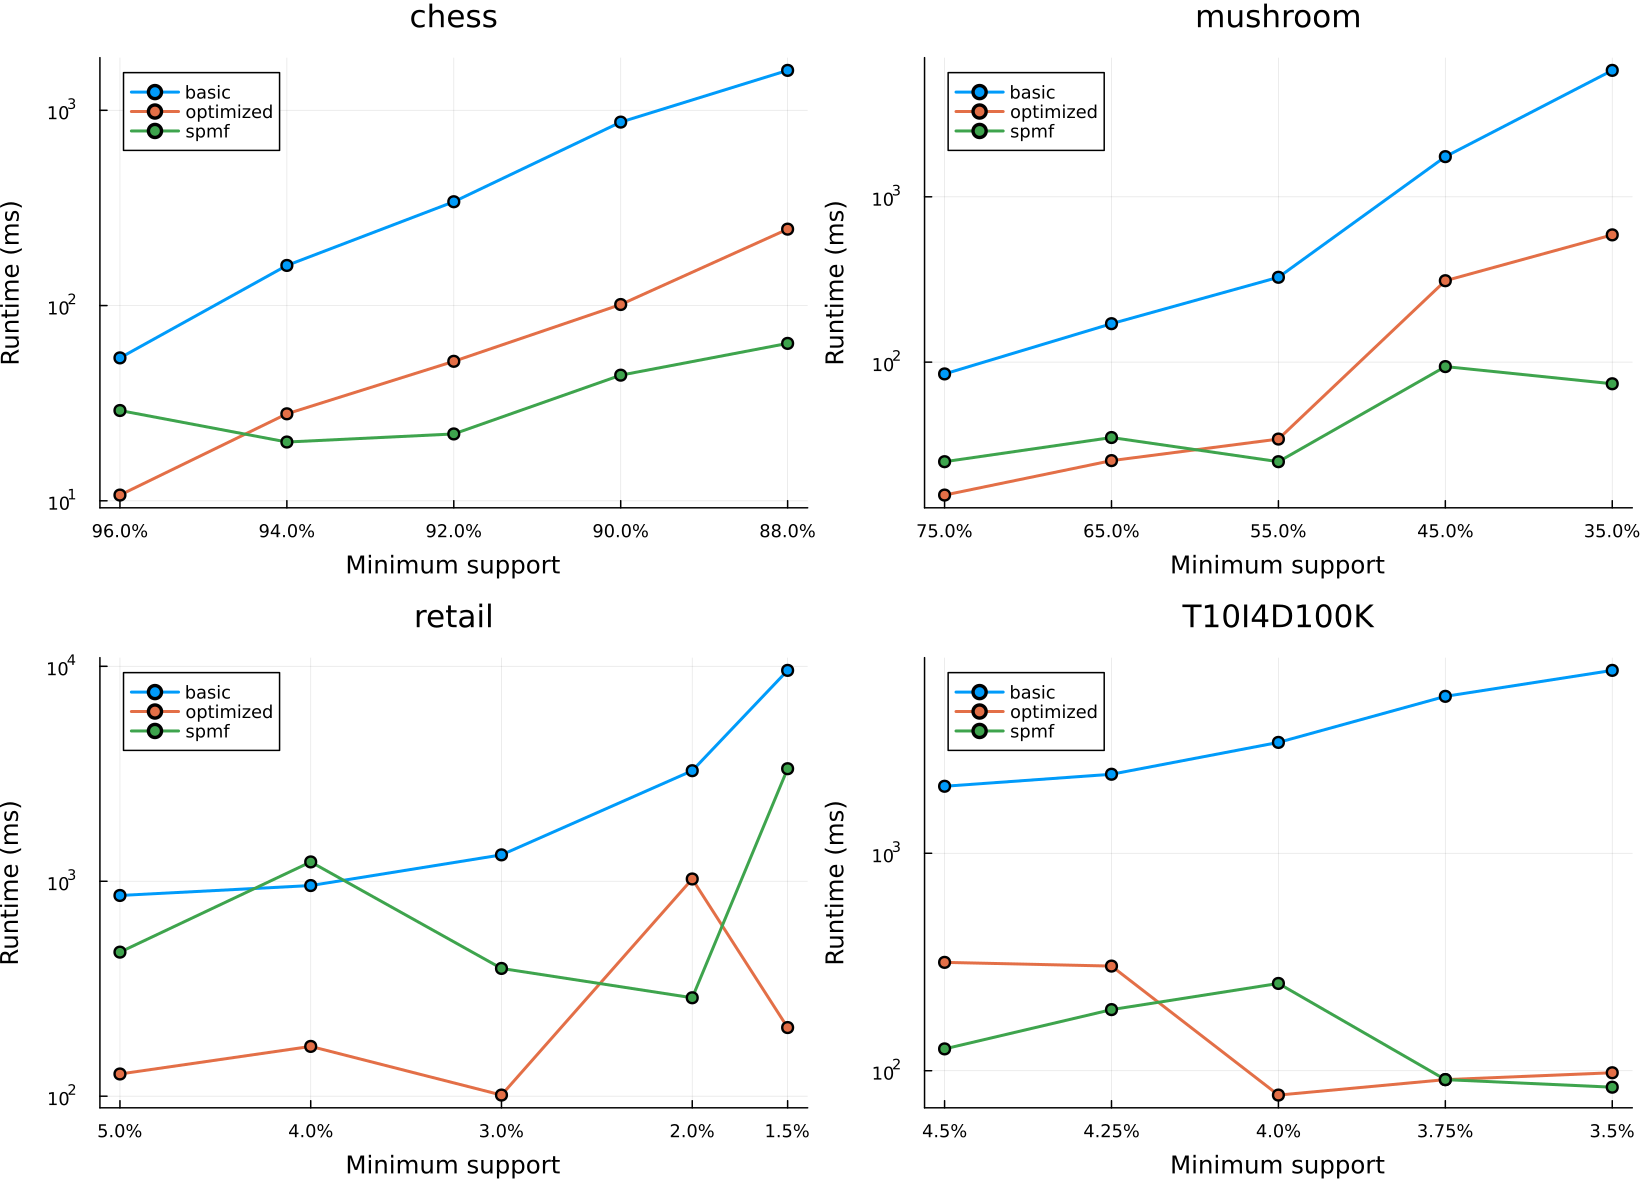

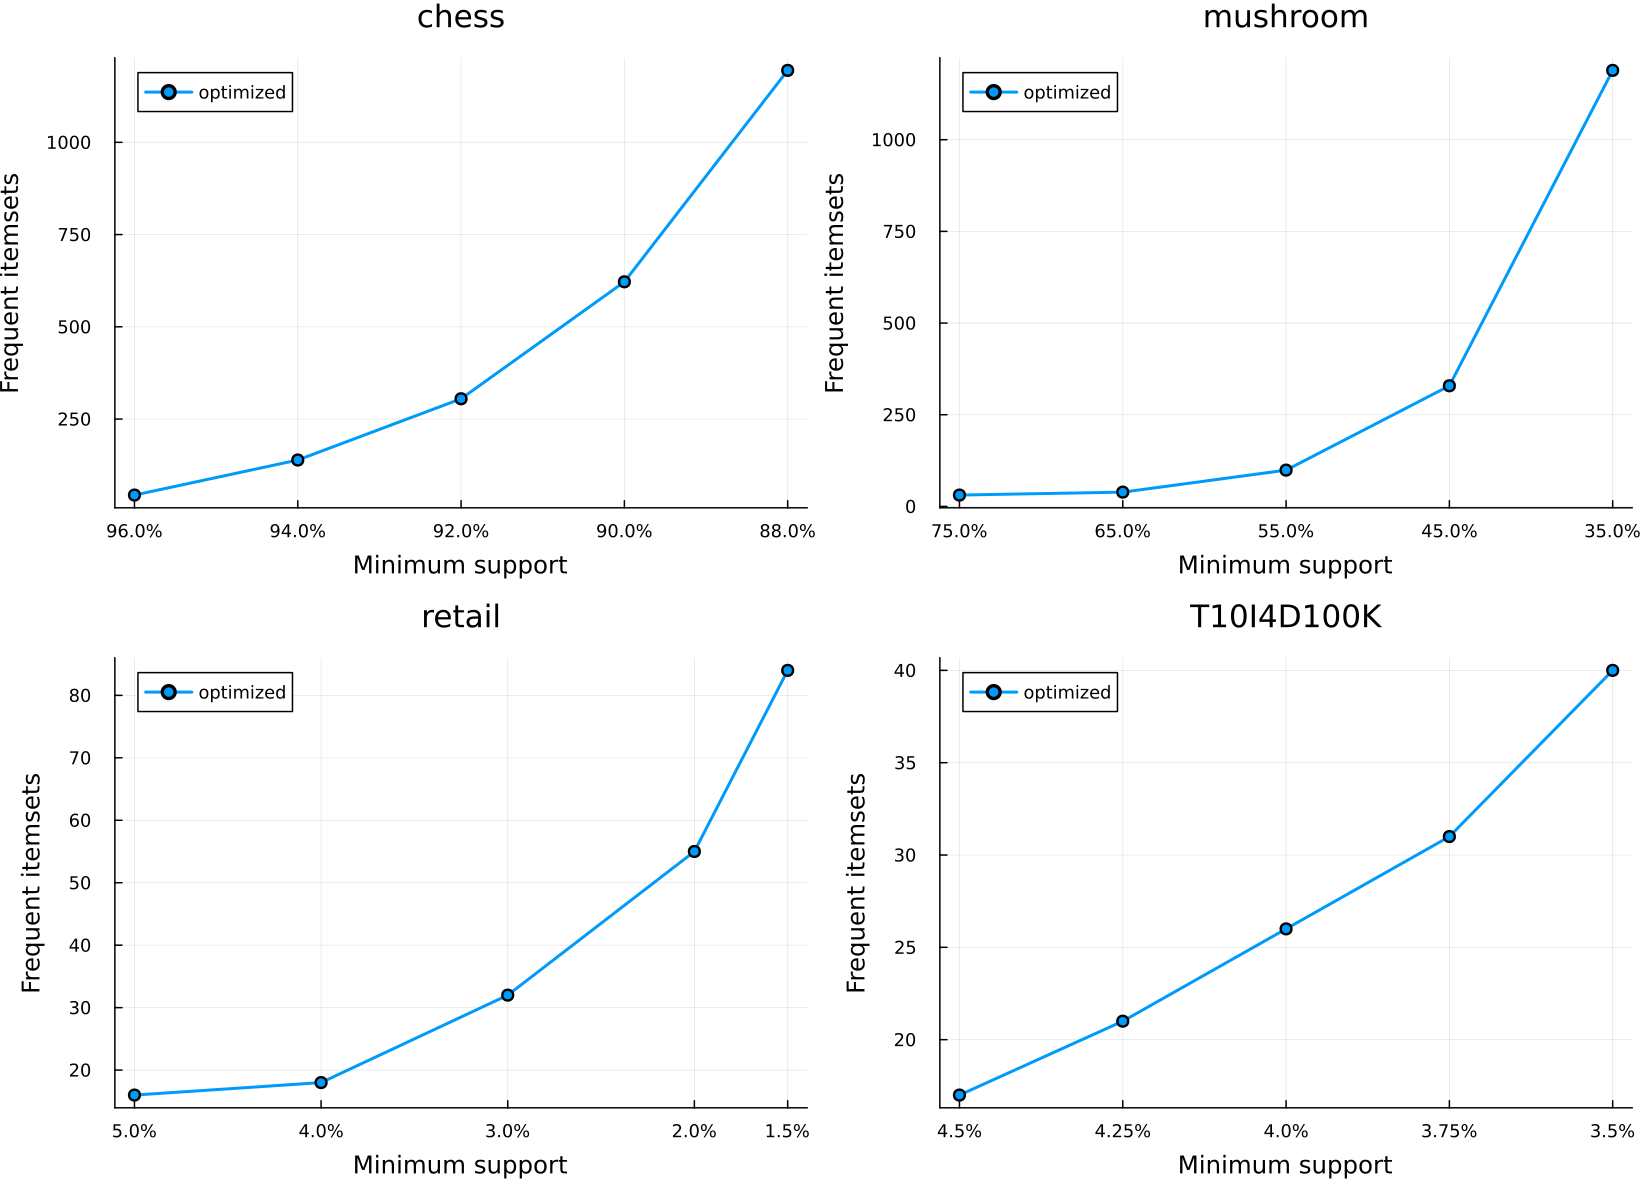

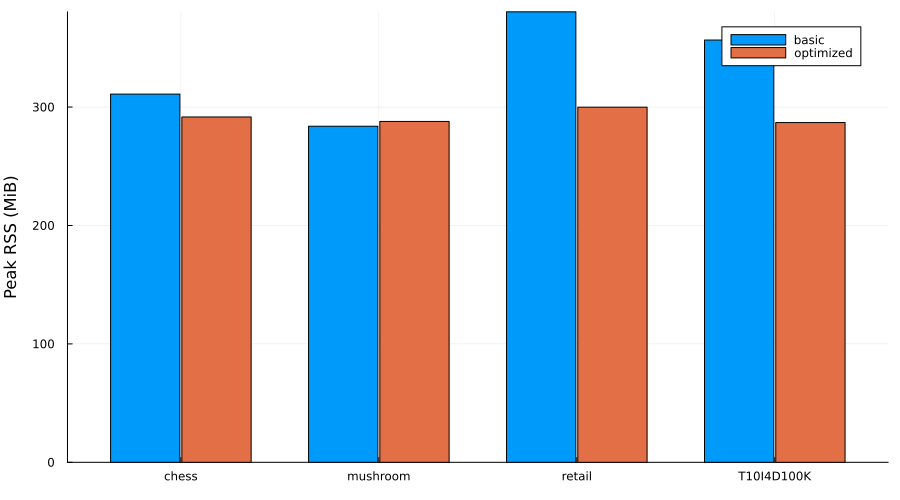

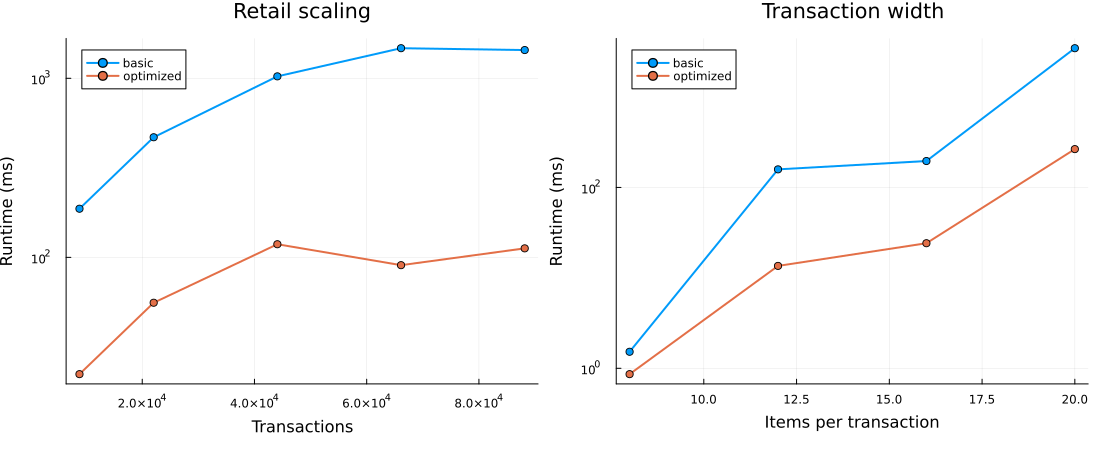

In [ ]:
run_full_benchmark = False  #@param {type:"boolean"}
if run_full_benchmark:
    benchmark_directory = workspace / "benchmark_new"
    run_julia(".", "scripts/run_benchmark.jl", benchmark_input_directory,
              benchmark_directory, spmf_jar, repository / "configs/benchmark.toml", threads=1)
    run_julia("evaluation_environment", "scripts/plot_results.jl", "benchmark", benchmark_directory)
    print("New benchmark results:", benchmark_directory)
else:
    benchmark_directory = repository / "result/final/benchmark"
    print("Saved final benchmark; source revision and measurement scope are recorded in result/final/run_manifest.toml.")

print((benchmark_directory / "environment.txt").read_text())
for filename in ("runtime_ms.png", "itemsets.png", "peak_ram.png", "scaling_and_width.png"):
    display(Image(filename=str(benchmark_directory / filename)))


## 5. Ứng dụng 1 — Market Basket Analysis
Tải dữ liệu Groceries gốc, chuyển giỏ hàng thành transaction, khai thác bằng Apriori-TID và tạo luật kết hợp. Minsup 1%, minconf 40%.

/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining/evaluation_environment /content/apriori-tid-mining/scripts/fetch_datasets.jl groceries --root /content/apriori-tid-mining/data/raw


/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining /content/apriori-tid-mining/scripts/run_market_basket.jl /content/apriori-tid-mining/data/raw/groceries/Groceries.data /content/apriori-tid-mining/data/raw/groceries/Groceries.labels /tmp/apriori-demo-zrqz1qsr/groceries 0.01 0.4 optimized


/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining/evaluation_environment /content/apriori-tid-mining/scripts/plot_results.jl groceries /tmp/apriori-demo-zrqz1qsr/groceries


antecedent,consequent,support_count,support,confidence,lift
"citrus fruit + root vegetables","other vegetables",102,0.010371123538383325,0.5862068965517241,3.0296084222733617
"root vegetables + tropical fruit","other vegetables",121,0.012302999491611592,0.5845410628019324,3.020999134344196
"rolls/buns + root vegetables","other vegetables",120,0.012201321809862735,0.502092050209205,2.594889812825818
"root vegetables + yogurt","other vegetables",127,0.012913065582104729,0.5,2.5840777719390435
"whipped/sour cream + yogurt","other vegetables",100,0.010167768174885612,0.49019607843137253,2.5334095803323957
"root vegetables + whole milk","other vegetables",228,0.023182511438739197,0.47401247401247404,2.4497701954349353
"onions","other vegetables",140,0.014234875444839857,0.45901639344262296,2.372268118501417
"pork + whole milk","other vegetables",100,0.010167768174885612,0.45871559633027525,2.3707135522376546
"whipped/sour cream + whole milk","other vegetables",144,0.014641586171835282,0.454

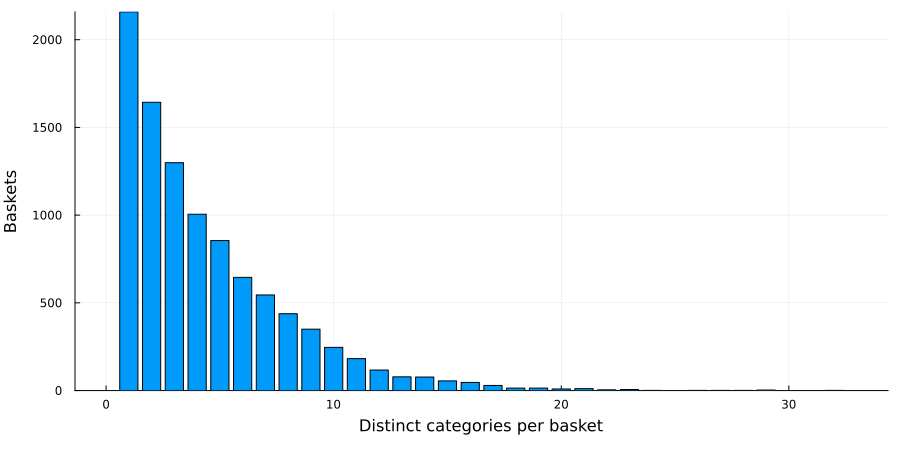

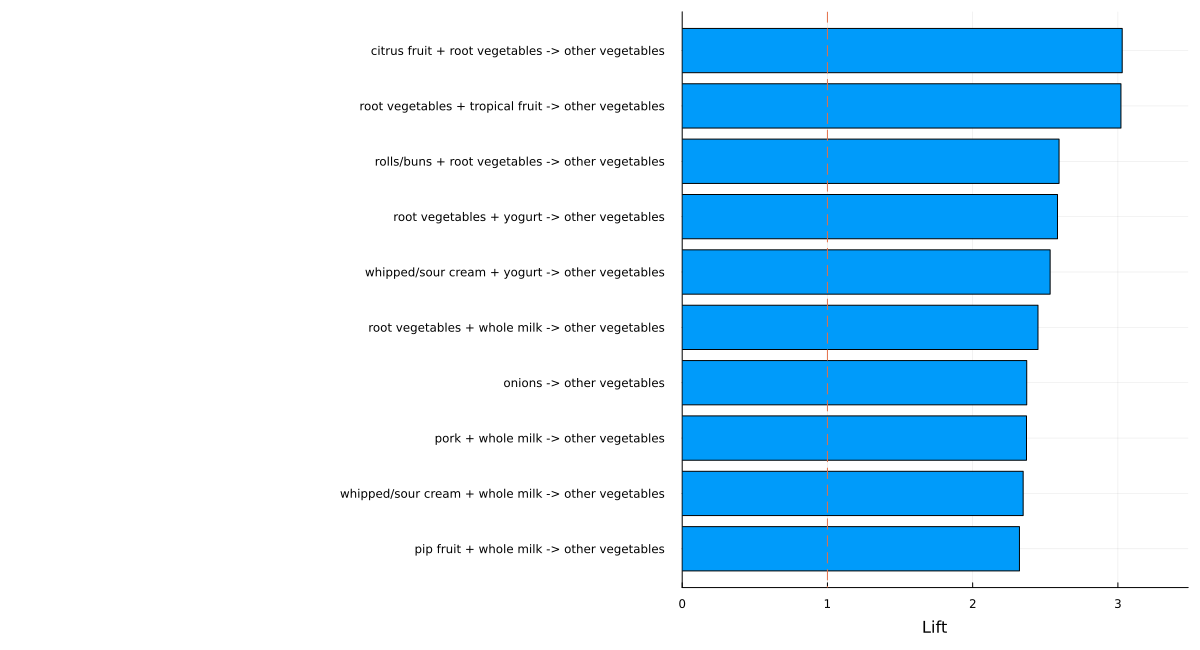

In [ ]:
groceries_output = workspace / "groceries"
run_julia("evaluation_environment", "scripts/fetch_datasets.jl", "groceries", "--root", raw_data)
run_julia(".", "scripts/run_market_basket.jl", raw_data / "groceries/Groceries.data",
          raw_data / "groceries/Groceries.labels", groceries_output, "0.01", "0.4", "optimized")
run_julia("evaluation_environment", "scripts/plot_results.jl", "groceries", groceries_output)
print((groceries_output / "top10_rules.csv").read_text())
for filename in ("basket_lengths.png", "top10_rules.png"):
    display(Image(filename=str(groceries_output / filename)))

## 6. Ứng dụng 2 — Visual Pattern Mining
Oxford Flowers-17 → thu nhỏ ảnh → trích xuất ORB → K-Means tạo visual vocabulary → chuyển mỗi ảnh thành một transaction → Apriori-TID optimized → kiểm tra support và hiển thị ảnh mẫu.

Ảnh không có descriptor vẫn đóng góp vào mẫu số support. Chạy toàn bộ 1.360 ảnh (`image_limit = 0`). Có thể đặt giới hạn nhỏ để kiểm tra nhanh; dữ liệu giới hạn lấy theo thứ tự tên file, không đại diện đủ 17 lớp.

/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining/visual_environment /content/apriori-tid-mining/scripts/visual_pipeline.jl --output /tmp/apriori-demo-zrqz1qsr/flowers_k8 --limit 0 --words 8 --maximum-descriptors 100 --seed 42 --minsup 0.7,0.8,0.9


training_descriptors = 18815
saturated_images = 1077
julia_version = "1.12.6"
dataset_url = "https://www.robots.ox.ac.uk/~vgg/data/flowers/17/17flowers.tgz"
descriptor = "ORB (ImageFeatures.jl)"
archive_sha256 = "fe38a60f8b4a95e657551247d3e7d799a3fafcdbc595be504b12839967823d70"
run_utc = "2026-11-24T13:25:20.207"
clustering = "K-Means (Clustering.jl)"
total_descriptors = 122744
maximum_descriptors = 100
images = 1360
maximum_side = 256
seed = 42
visual_words = 8
empty_transactions = 2
valid_images = 1360

minimum_support,absolute_minimum_support,num_transactions,num_patterns,seconds,implementation
0.7,952,1360,255,2.854831745,optimized
0.8,1088,1360,250,0.027716989,optimized
0.9,1224,1360,47,0.014434139,optimized



# Visual Pattern Mining Analysis

Images and transactions: 1360.

- Minsup 0.7: 255 frequent itemsets.
- Minsup 0.8: 250 frequent itemsets.
- Minsup 0.9: 47 frequent itemsets.

Images containing all 8 visual words: 1077/1360 (79.19%).
Average visual words per image: 7.58.
High saturation can reduce the ability of patterns to distinguish images. Compare a larger K or fewer descriptors on the same images.
Each pattern can be used as a binary feature for classification or image retrieval. Evaluate on an independent test set before drawing conclusions.

ORB describes local image regions. Visual words are descriptor clusters, not necessarily specific flower parts.
Transactions discard spatial positions and repetitions. K, seed and image size affect results; co-occurrence does not establish classification performance.


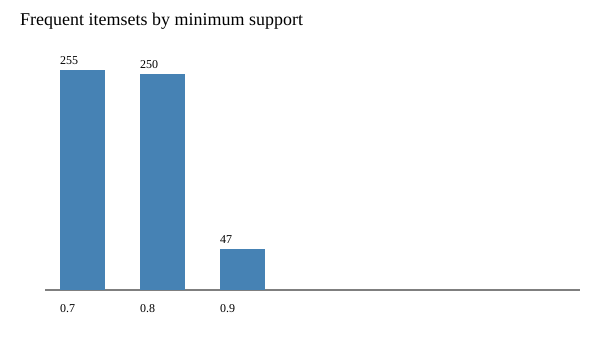

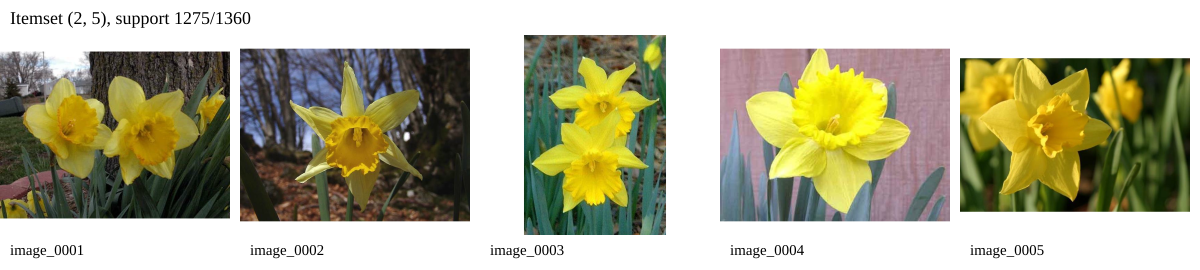

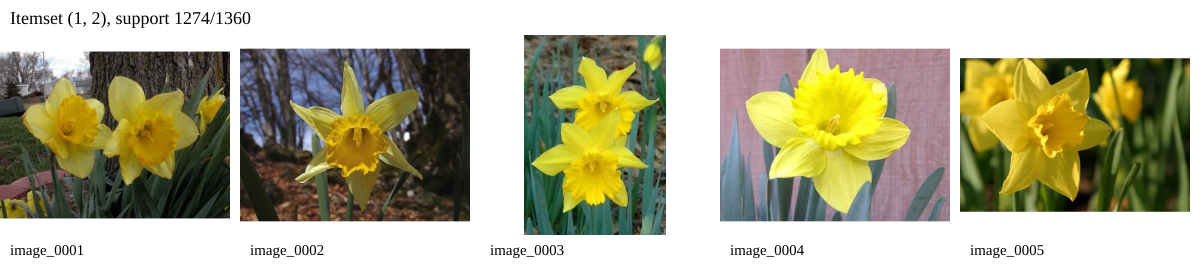

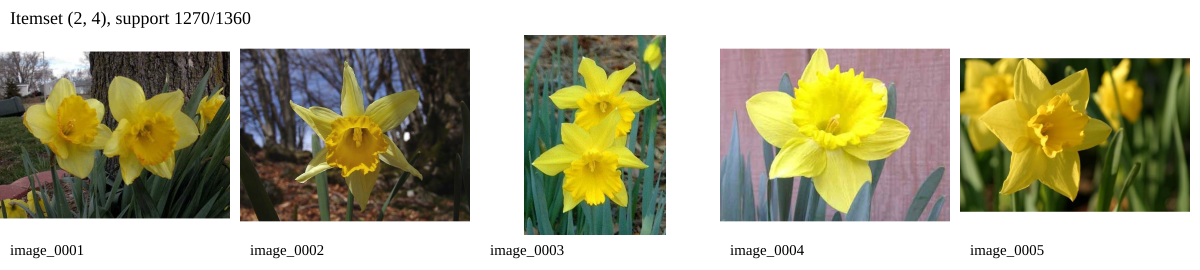

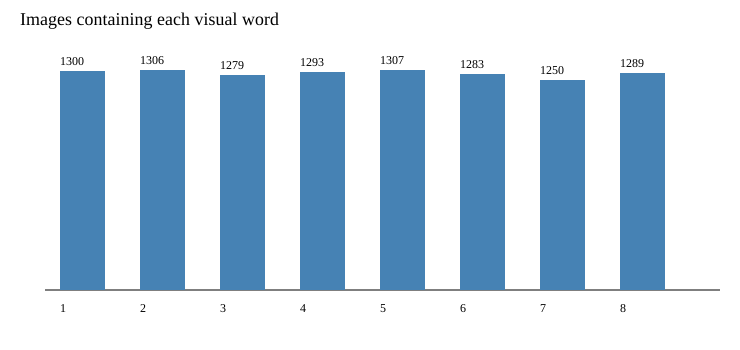

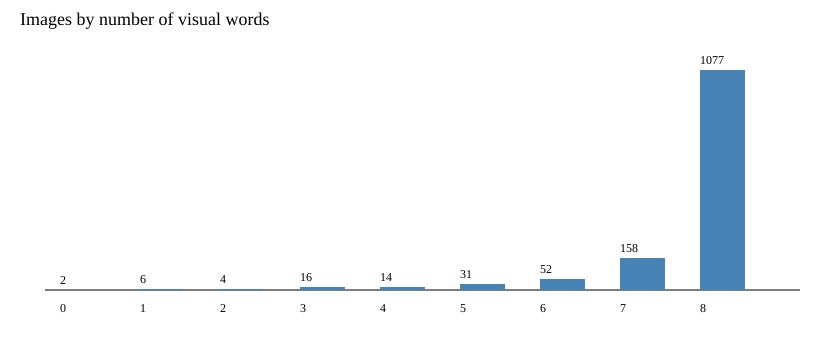

In [ ]:
image_limit = 0
visual_words = 8
maximum_descriptors = 100
minimum_support_values = "0.7,0.8,0.9"
visual_output = workspace / "flowers_k8"

run_julia("visual_environment", "scripts/visual_pipeline.jl", "--output", visual_output,
          "--limit", image_limit, "--words", visual_words, "--maximum-descriptors", maximum_descriptors,
          "--seed", 42, "--minsup", minimum_support_values)
print((visual_output / "dataset_summary.toml").read_text())
print((visual_output / "runs.csv").read_text())
display(Markdown((visual_output / "analysis.md").read_text()))
for figure_path in sorted((visual_output / "figures").glob("*.svg")):
    display(SVG(filename=str(figure_path)))

## 7. Thử cấu hình ảnh khác
Tăng số cụm lên 16, giảm số ORB mỗi ảnh còn 40 để xem các giao dịch có bớt bão hòa hay không. Giữ nguyên tập ảnh, seed và các minsup để đối chiếu. Hai tham số thay đổi đồng thời nên đây là so sánh cấu hình, không phải thí nghiệm tách riêng ảnh hưởng từng tham số.

/usr/local/bin/julia --startup-file=no --project=/content/apriori-tid-mining/visual_environment /content/apriori-tid-mining/scripts/visual_pipeline.jl --output /tmp/apriori-demo-zrqz1qsr/flowers_k16 --limit 0 --words 16 --maximum-descriptors 40 --seed 42 --minsup 0.7,0.8,0.9


training_descriptors = 18815
saturated_images = 8
julia_version = "1.12.6"
dataset_url = "https://www.robots.ox.ac.uk/~vgg/data/flowers/17/17flowers.tgz"
descriptor = "ORB (ImageFeatures.jl)"
archive_sha256 = "fe38a60f8b4a95e657551247d3e7d799a3fafcdbc595be504b12839967823d70"
run_utc = "2026-11-24T13:27:21.377"
clustering = "K-Means (Clustering.jl)"
total_descriptors = 52459
maximum_descriptors = 40
images = 1360
maximum_side = 256
seed = 42
visual_words = 16
empty_transactions = 2
valid_images = 1360

minimum_support,absolute_minimum_support,num_transactions,num_patterns,seconds,implementation
0.7,952,1360,11,0.174001109,optimized
0.8,1088,1360,0,0.00225972,optimized
0.9,1224,1360,0,0.00143012,optimized



# Visual Pattern Mining Analysis

Images and transactions: 1360.

- Minsup 0.7: 11 frequent itemsets.
- Minsup 0.8: 0 frequent itemsets.
- Minsup 0.9: 0 frequent itemsets.

Images containing all 16 visual words: 8/1360 (0.59%).
Average visual words per image: 11.38.
High saturation can reduce the ability of patterns to distinguish images. Compare a larger K or fewer descriptors on the same images.
Each pattern can be used as a binary feature for classification or image retrieval. Evaluate on an independent test set before drawing conclusions.

ORB describes local image regions. Visual words are descriptor clusters, not necessarily specific flower parts.
Transactions discard spatial positions and repetitions. K, seed and image size affect results; co-occurrence does not establish classification performance.


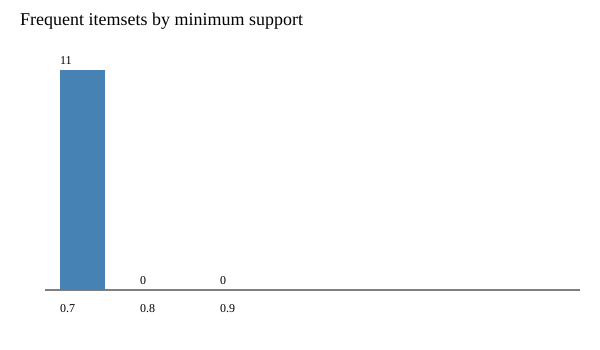

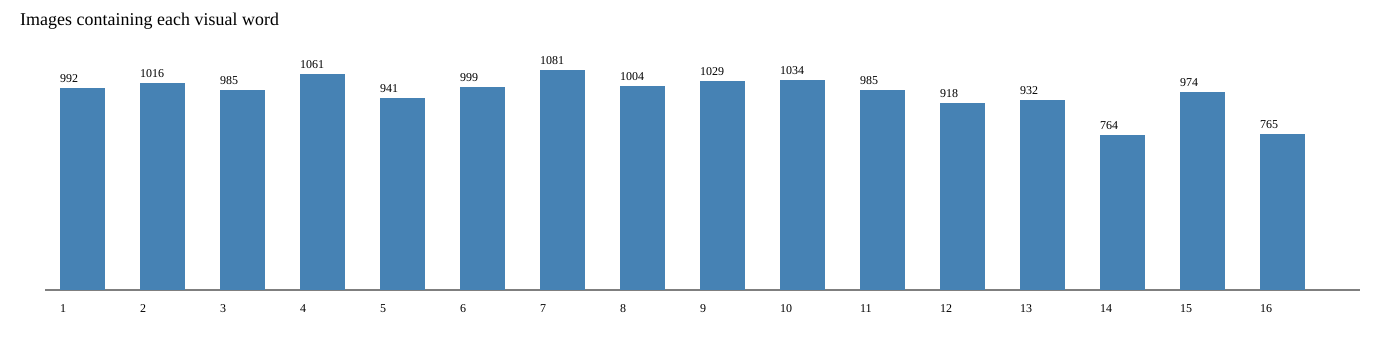

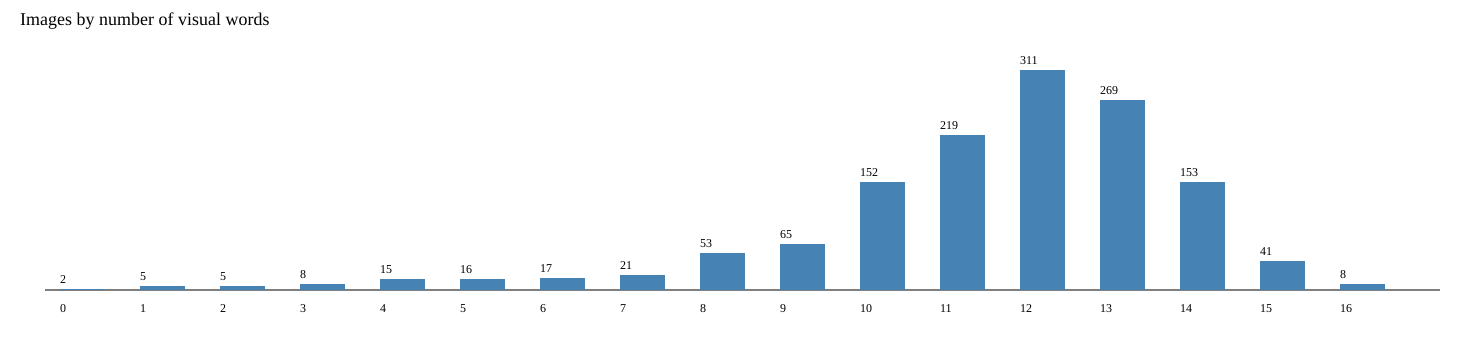

In [ ]:
alternative_output = workspace / "flowers_k16"
run_julia("visual_environment", "scripts/visual_pipeline.jl", "--output", alternative_output,
          "--limit", image_limit, "--words", 16, "--maximum-descriptors", 40,
          "--seed", 42, "--minsup", minimum_support_values)
print((alternative_output / "dataset_summary.toml").read_text())
print((alternative_output / "runs.csv").read_text())
display(Markdown((alternative_output / "analysis.md").read_text()))
for figure_path in sorted((alternative_output / "figures").glob("*.svg")):
    display(SVG(filename=str(figure_path)))

## 8. Tổng kết
Groceries dùng luật kết hợp để gợi ý giả thuyết mua kèm, không chứng minh quan hệ nhân quả. Visual patterns có thể tạo đặc trưng nhị phân cho phân loại hoặc truy vấn ảnh; cần đo hiệu quả trên tập kiểm tra riêng. Kết quả mới nằm trong thư mục workspace được in ở dưới. Không sử dụng benchmark cũ làm bằng chứng kiểm thử của code mới.

In [ ]:
print("Output directory:", workspace)

Output directory: /tmp/apriori-demo-zrqz1qsr
